# Lab 4  Solving a classification problem using techniques in Workshop 4
Develop classifiers using the techniques covered in Workshop 4 to predict the class label of a new Iris flower.

## Solving a classification problem
In order to solve a classification problem, the following steps need to be taken:
1. Find a suitable dataset
2. Define the input dataset
3. Explore the input dataset.
After exploration, it may be needed to pre-process the dataset in real-world classification problems, i.e., to clean and pre-process the input dataset to make it ready for model development. In this example, the dataset is clean so there is no need for pre-processing.
4. Form the train, validation and test datasets
5. Develop a classifier by training a machine learning model based on a chosen algorithm using the train dataset and validate the performance using the validation dataset
6. Evaluate the classifier's performance using unseen test dataset
7. Deploy the classifier to solve the target classification problem (not covered in this notebook)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Findnig a Dataset

The dataset is from the Iris Plants Database. https://gist.github.com/curran/a08a1080b88344b0c8a7

Relevant Information about this dataset is as follows:
This is perhaps the best known database to be found in the pattern recognition literature.  The data set contains 3 classes of 50 instances each, where each class refers to a type of iris plant.  One class is linearly separable from the other 2; the latter are NOT linearly separable from each other.
* Predicted attribute: class of iris plant.
* This is an exceedingly simple domain.
* Number of Instances: 150 (50 in each of three classes)
* Number of Attributes: 4 numeric, predictive attributes and the class
* Attribute Information:
-- sepal length in cm
-- sepal width in cm
-- petal length in cm
-- petal width in cm
-- class: Iris Setosa, Iris Versicolour and Iris Virginica

The class is the target attribute or variable.

### Image samples of these three classes are shown in the following cells, respectively.

In [2]:
cd /content/drive/MyDrive/IntroAILab2025/Assignment2/Weather Prediction

/content/drive/.shortcut-targets-by-id/1kLPoKDXN-nt0qPNvEL4GxcyJh_Mq6ON1/Assignment2/Weather Prediction


## Section 1

In [3]:
# Import required packages
import pandas as pd
import numpy as np
from itertools import product

from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.metrics import accuracy_score

from sklearn.preprocessing import StandardScaler

In [4]:
# Task
# Load the dataset by reading the iris.csv file using read_csv() method and save the output as a dataframe

"Add your code here"
weather = pd.read_csv("seattle-weather.csv")

In [5]:
# Take a look at the first 5 samples of iris using the method head() of a pandas dataframe
weather

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain
...,...,...,...,...,...,...
1456,2015-12-27,8.6,4.4,1.7,2.9,rain
1457,2015-12-28,1.5,5.0,1.7,1.3,rain
1458,2015-12-29,0.0,7.2,0.6,2.6,fog
1459,2015-12-30,0.0,5.6,-1.0,3.4,sun


# My Note

Encoder to convert the label to numbers.

In [6]:
# import LabelEncoder from sklearn.preprocessing
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()  # Instantiate the encoder

In [7]:
# Convert categorical target values into numeric values using the encoder 'le' by fitting the encoder and transforming the target column
weather['weather'] = le.fit_transform(weather['weather'])

In [8]:
# Take a look at the first 5 samples of iris using the method head() of a dataframe again after converting the target values
weather

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,0
1,2012-01-02,10.9,10.6,2.8,4.5,2
2,2012-01-03,0.8,11.7,7.2,2.3,2
3,2012-01-04,20.3,12.2,5.6,4.7,2
4,2012-01-05,1.3,8.9,2.8,6.1,2
...,...,...,...,...,...,...
1456,2015-12-27,8.6,4.4,1.7,2.9,2
1457,2015-12-28,1.5,5.0,1.7,1.3,2
1458,2015-12-29,0.0,7.2,0.6,2.6,1
1459,2015-12-30,0.0,5.6,-1.0,3.4,4


## Section 2

### Form the train, validation and test datasets. Also take a few future samples from the test dataset

#### Create the train dataset (60%), validation dataset (20%) and test dataset (20%).

In [9]:
# Task

# Import train_test_split from sklearn.model.selection
"Add your code here"
from sklearn.model_selection import train_test_split

In [10]:
# Task

# Define the input features X as all columns except 'species' column by using drop() method for a dataframe and target variable y as the "species" column
X = weather.drop(['date', 'weather'], axis=1)
# print(X)
y = weather["weather"]

In [11]:
# Task

# Using train_test_split function to split the dataset into the train and temp (validation plus test) datasets, the percentage of samples in the temp dataset is 40% and the seed for the random number generator is 42

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)

In [12]:
# Task

# Using train_test_split function to split the temp (validation plus test) datasets into the validation and test datasets, the percentage of samples in the test dataset is 20% and the seed for the random number generator is 42

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [13]:
# Make a futureSample test dataset
# Take two samples from the dataset as the future data samples, called futureSample_X, and futureSample_y,
# as the inputs from the real-world cases when the classifier is deployed.

# Get the last two samples from the test  to be the future data samples
futureSample_X = X_test[-2:]
futureSample_y = y_test[-2:]

# Remove the last two samples from the test dataset
X_test = X_test[:-2]
y_test = y_test[:-2]

## Section 3

### Explore the train, validation and test datasets

In [14]:
# import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

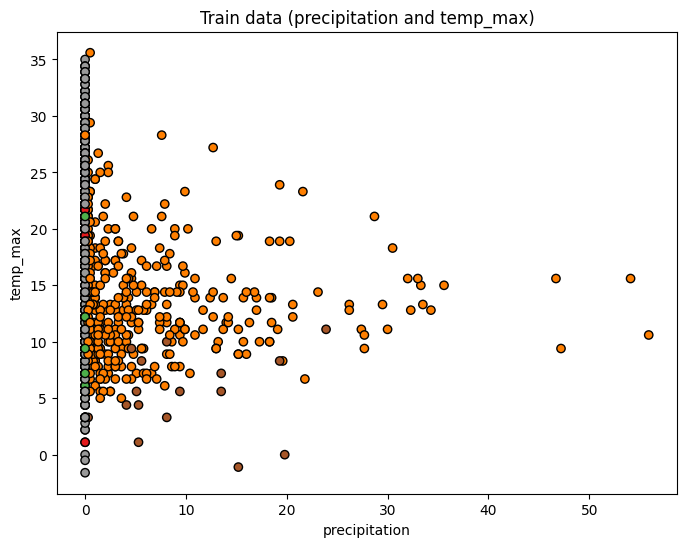

In [15]:
# Explore the train dataset
# Plot the samples in the train dataset (use the first two attributes)
plt.figure(figsize=(8, 6))
plt.scatter(X_train['precipitation'], X_train['temp_max'], c=y_train, cmap=plt.cm.Set1, edgecolor="k")
plt.xlabel("precipitation")
plt.ylabel("temp_max")
plt.title("Train data (precipitation and temp_max)")
plt.show()

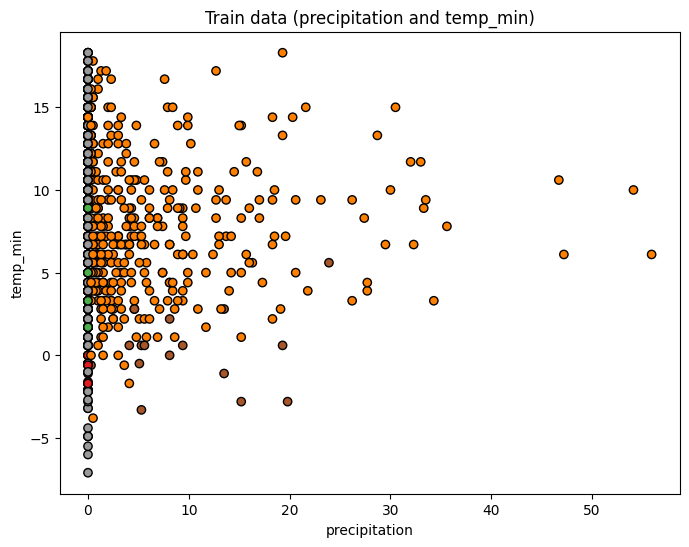

In [16]:
# Plot the samples in the train dataset (use the last two attributes)
plt.figure(figsize=(8, 6))
plt.scatter(X_train['precipitation'], X_train['temp_min'], c=y_train, cmap=plt.cm.Set1, edgecolor="k")
plt.xlabel("precipitation")
plt.ylabel("temp_min")
plt.title("Train data (precipitation and temp_min)")
plt.show()

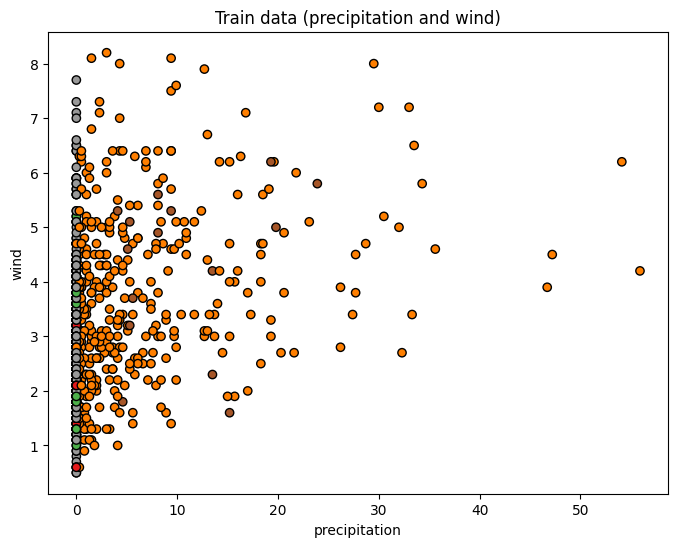

In [17]:
# Explore the validation dataset
# Plot the samples in the validation dataset (use the first two attributes)
plt.figure(figsize=(8, 6))
plt.scatter(X_train['precipitation'], X_train['wind'], c=y_train, cmap=plt.cm.Set1, edgecolor="k")
plt.xlabel("precipitation")
plt.ylabel("wind")
plt.title("Train data (precipitation and wind)")
plt.show()

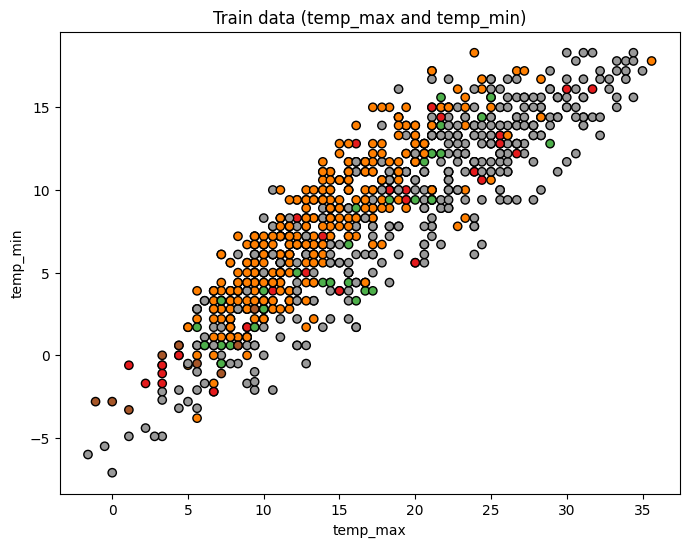

In [18]:
# Plot the samples in the validation dataset (use the last two attributes)
plt.figure(figsize=(8, 6))
plt.scatter(X_train['temp_max'], X_train['temp_min'], c=y_train, cmap=plt.cm.Set1, edgecolor="k")
plt.xlabel("temp_max")
plt.ylabel("temp_min")
plt.title("Train data (temp_max and temp_min)")
plt.show()

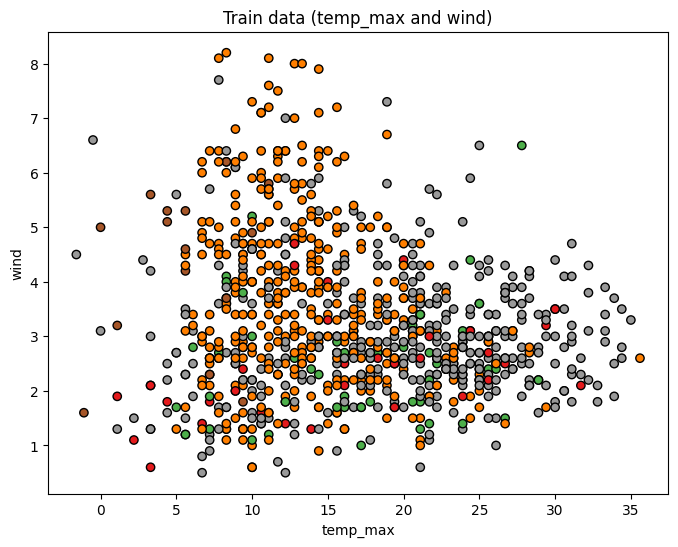

In [19]:
# Plot the samples in the test dataset (use the first two attributes)
plt.figure(figsize=(8, 6))
plt.scatter(X_train['temp_max'], X_train['wind'], c=y_train, cmap=plt.cm.Set1, edgecolor="k")
plt.xlabel("temp_max")
plt.ylabel("wind")
plt.title("Train data (temp_max and wind)")
plt.show()

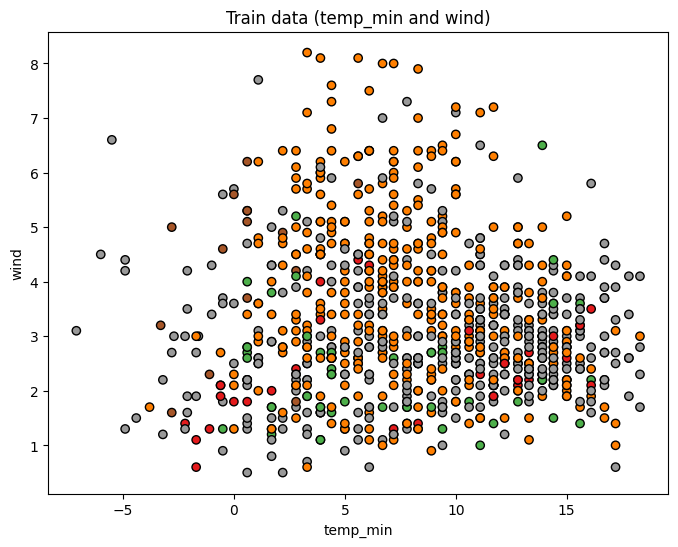

In [20]:
# Plot the samples in the test dataset (use the last two attributes)
plt.figure(figsize=(8, 6))
plt.scatter(X_train['temp_min'], X_train['wind'], c=y_train, cmap=plt.cm.Set1, edgecolor="k")
plt.xlabel("temp_min")
plt.ylabel("wind")
plt.title("Train data (temp_min and wind)")
plt.show()

## Section 4

### Train a classification model by using a chosen learning algorithm with the train dataset.

***First***, take an integer in the range of 1-5 from the user and save it to `model_option` to represent a model.

model_option: 1- decision tree, 2- Random forest, 3-logistic regression, 4-K nearest neighbours, or 5 -- Support vector classifier

If a user enters a number  >5, print out a message "invalid option number. Try again".

***Second***, train the model using the train dataset

***Third***, tune the hyperparameters of the model using the vaidation dataset

***Fourth***, evaluate the model using the test dataset

***Lastly***, consume the model using the futureSample test dataset


In [21]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

In [22]:
# y_train.value_counts()

In [23]:
model_option = int(input("Choose one model from the following: 1- decision tree, 2- Random forest, 3- logistic regression, 4-K nearest neighbours, or 5- Support vector classifier \n your choice is: "))

if model_option == 1:
    #  Task: Import `DecisionTreeClassifier` from `sklearn.tree`.
    "Add your code here"
    from sklearn.tree import DecisionTreeClassifier

    """
    The constructor `DecisionTreeClassifier()` is used to create a decision tree classifier object by passing the following key parameters:
    (i) "criterion", which represents the measure used in expanning the decision tree.
         There are a number of options for this parameter, such as `gini` (Gini impurity) and `entropy` or 'log_loss(information gain).
         By default, it is `gini`. We use `entropy`.
    (ii) "splitter": The strategy used to choose the split at each node.
          Supported strategies are “best” to choose the best split and “random” to choose the best random split. Default is ”best”.
    (iii) "max_depth": Maximum depth of the tree. If None, nodes are expanded until all leaves are pure or contains fewer than `min_samples_split`
    (iv) "min_sample_split": Minimum number of samples required to split an internal node, default is 2
    (v) "min_samples_leaf" Minimum number of samples required to be at a leaf node. default is 1.
    (vi) "max_features": number of features to consider when looking for the best split, default is None (max_features=n_features).
        Other values are 'sqrt' (max_features=sqrt(n_features)) and "log2” (max_features=log2(n_features))
    (vii) "random_state": Controls the randomness of the estimator. default is None.
          To obtain a deterministic behaviour during fitting, random_state has to be fixed to an integer, say random_state = 42.
    """
    # Define model + hyperparameter grid (tuned *on validation set*)
    param_grid = {
      "criterion": ["gini", "entropy"],     # impurity metrics
      "max_depth": [None, 2, 3, 4, 5],
      "min_samples_split": [2, 5, 10],
      "min_samples_leaf": [1, 2, 4],
    }

    fixed_params = {
      "random_state": 42
    }

    # Define evaluation function
    def evaluate_on_val(params):
      clf = DecisionTreeClassifier(**fixed_params, **params)
      clf.fit(X_train, y_train)
      preds = clf.predict(X_val)
      return accuracy_score(y_val, preds), clf

    # Manual grid search using validation accuracy (break ties by shallower depth)
    results = []
    best_acc = -np.inf
    best_clf = None
    best_params = None
    best_tie_metric = None  # smaller = better (depth, node_count)

    keys, values = zip(*param_grid.items())
    for combo in product(*values):
      params = dict(zip(keys, combo))
      try:
        acc, model = evaluate_on_val(params)
        depth = model.get_depth()
        nodes = model.tree_.node_count
        results.append({**params, "val_acc": acc, "depth": depth, "nodes": nodes})
        tie_metric = (depth, nodes)

        if (acc > best_acc) or (np.isclose(acc, best_acc) and tie_metric < best_tie_metric):
            best_acc = acc
            best_clf = model
            best_params = params
            best_tie_metric = tie_metric
      except Exception as e:
        results.append({**params, "val_acc": np.nan, "depth": np.nan, "nodes": np.nan})
        print(f"Skipped {params} due to: {e}")

    # Show validation results sorted
    df_results = pd.DataFrame(results).sort_values(["val_acc","depth","nodes"], ascending=[False, True, True])
    print("\nValidation results (top 10):")
    print(df_results.head(10).to_string(index=False))

    print("\nBest on validation:")
    print(best_params, "val_acc=", round(best_acc, 4), "depth=", best_tie_metric[0], "nodes=", best_tie_metric[1])

    # Refit best model on TRAIN + VAL
    X_train_val = np.vstack([X_train, X_val])
    y_train_val = np.hstack([y_train, y_val])

    final_clf = DecisionTreeClassifier(**fixed_params, **best_params)
    final_clf.fit(X_train_val, y_train_val)

    # Task
    # Predict the class labels of samples in the test dataset using the final nodel, final_clf, to do final evaluation on the untouched TEST set
    # y_pred = "Add your code here"

    # Solution
    # Predict the class labels of samples in the test dataset using the final nodel, final_clf, to do final evaluation on the untouched TEST set
    y_pred = final_clf.predict(X_test)

elif model_option == 2:
    # Task: Import RandomForestClassifier from sklearn.ensemble.
    "Add your code here"
    from sklearn.ensemble import RandomForestClassifier
    """
    The constructor RandomForestClassifier() is used to create a RandomForestClassifier object by passing the following parameters:
    (i) n_estimator: Number of trees in the forest, default is 100
    (ii) "criterion", which represents the measure used in expanning the decision tree.
         There are a number of options for this parameter, such as `gini` (Gini impurity) and `entropy` or 'log_loss(information gain).
         By default, it is `gini`. We use `entropy`.
    (iii) max_depth: Maximum depth of the trees,
         default is None (nodes are expanded until all leaves are pure or
         until they contain fewer than 'min_sample_split' samples)
    (iv) min_samples_split: Minum number of samples required to split an internal node, default is 2
    (v) min_samples_leaf: Minum number of samples required to be at a leaf node, default is 1
    (vi) max_features: number of features to consider when looking for the best split, default is None (max_features=n_features).
        Other values are 'sqrt' (max_features=sqrt(n_features)) and "log2” (max_features=log2(n_features))
    (vii) 'bootstrap: Whether to use bootstrap samples when building trees, default is 'True'.
          If 'False', the entire dataset is used to build each tree, which may lead to overfitting.
    (viii) oob_score: Whether to use out-of-bag samples to estimate the generalisation accuracy.
          default value is 'False'. If 'True', an unbiased estimate of the model performance is provided.
    """
    # Define model + hyperparameter grid (tuned *on validation set*)
    param_grid = {
      "n_estimators": [50, 100, 200],
      "criterion": ["gini","entropy"],
      "max_depth": [None, 3, 5, 8],
      "min_samples_split": [2, 5, 10],
      "min_samples_leaf": [1, 2, 4],
      "max_features": ["sqrt", "log2"]  # 'auto' is deprecated
    }

    fixed_params = {

      "random_state": 42,
   #   "n_jobs": -1,
      "oob_score": True,   # OOB uses training data only; helpful as an internal check
      "bootstrap": True
    }

    # Define evaluation function
    def evaluate_on_val(params):
      clf = RandomForestClassifier(**fixed_params, **params)
      clf.fit(X_train, y_train)                 # fit on TRAIN only
      val_preds = clf.predict(X_val)            # evaluate on VALIDATION
      val_acc = accuracy_score(y_val, val_preds)
      oob = getattr(clf, "oob_score_", np.nan)  # OOB score (training internal estimate)
      return val_acc, oob, clf

    # Manual grid search using validation accuracy (break ties by shallower depth)
    results = []
    best = {"acc": -np.inf, "params": None, "clf": None}

    def tie_key(p):
      # Prefer simpler models when validation accuracies tie:
      # fewer trees, shallower depth, larger leaves/splits (more regularization)
      depth_val = 10**6 if p["max_depth"] is None else p["max_depth"]
      return (p["n_estimators"], depth_val, -p["min_samples_leaf"], -p["min_samples_split"])

    keys, values = zip(*param_grid.items())
    for combo in product(*values):
      params = dict(zip(keys, combo))
      try:
        acc, oob, clf = evaluate_on_val(params)
        row = {**params, "val_acc": acc, "oob_score": oob}
        results.append(row)

        if (acc > best["acc"]) or (np.isclose(acc, best["acc"]) and tie_key(params) < tie_key(best["params"])):
            best = {"acc": acc, "params": params, "clf": clf}
      except Exception as e:
        results.append({**params, "val_acc": np.nan, "oob_score": np.nan})
        print(f"Skipped {params} due to: {e}")

    # Show validation results sorted
    df_results = pd.DataFrame(results).sort_values(["val_acc","n_estimators","max_depth"], ascending=[False, True, True])
    print("\nValidation results (top 10):")
    print(df_results.head(10).to_string(index=False))

    print("\nBest on validation:")
    print(best["params"], "val_acc=", round(best["acc"], 4))

    # Refit best model on TRAIN + VAL (finalize before testing)
    X_train_val = np.vstack([X_train, X_val])
    y_train_val = np.hstack([y_train, y_val])

    final_clf = RandomForestClassifier(**fixed_params, **best["params"])
    final_clf.fit(X_train_val, y_train_val)

    # Task
    # Predict the class labels of samples in the test dataset using the final nodel, final_clf, to do final evaluation on the untouched TEST set
    y_pred = "Add your code here"

    # Solution
    # Predict the class labels of samples in the test dataset using the final nodel, final_clf, to do final evaluation on the untouched TEST set
    y_pred = final_clf.predict(X_test)

elif model_option == 3:
    # Task: Import LogisticRegression from sklearn.linear_model.
    "Add your code here"
    from sklearn.linear_model import LogisticRegression
    """
    The constructor LogisticRegression() is uded to create a LogisticRegresion object by passing the following parameters:.
    (i) 'penalty':   Specify the norm of the penalty.
         Possible values: None (no penalty); 'l2' (add a L2 penalty term);
         'l1' (add a L1 penalty term); 'elasticnet' (both L1 and L2 penalty terms are added).  Default is l2
    (ii) 'dual': Dual (constrained) or primal (regularized) formulation. Default is False.
         Dual formulation is only implemented for l2 penalty with liblinear solver.
    (iii) 'random_state': Used when solver == ‘sag’, ‘saga’ or ‘liblinear’ to shuffle the data. Default is None

    (iv)'solver': Algorithm to use in the optimization problem.
         possible values: ‘lbfgs’, ‘liblinear’, ‘newton-cg’, ‘newton-cholesky’, ‘sag’, and ‘saga’. Default is ’lbfgs’
         To choose a solver, you might want to consider the following aspects
         (more info see https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html):
          -- For small datasets, ‘liblinear’ is a good choice, whereas ‘sag’ and ‘saga’ are faster for large ones;
          -- For multiclass problems, only ‘newton-cg’, ‘sag’, ‘saga’ and ‘lbfgs’ handle multinomial loss;
          -- ‘liblinear’ and ‘newton-cholesky’ can only handle binary classification by default.
          -- To apply a one-versus-rest scheme for the multiclass setting one can wrapt it with the OneVsRestClassifier.
          -- ‘newton-cholesky’ is a good choice for n_samples >> n_features, especially with one-hot encoded categorical features with rare categories.
             Be aware that the memory usage of this solver has a quadratic dependency on n_features because it explicitly computes the Hessian matrix.
    (v) 'max_iter': Maximum number of iterations taken for the solvers to converge. Default is 100.
    """
    # Define model + hyperparameter grid (tuned *on validation set*)
    param_grid = {
      "C": [0.01, 0.1, 1.0, 3.0, 10.0],
      "solver": ["lbfgs", "liblinear"],
    }
    fixed_params = {
      "max_iter": 1000,
      "multi_class": "auto",
      "penalty": "l2",
    }

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_val_s   = scaler.transform(X_val)

    # Define evaluation function
    def evaluate_on_val(C, solver):
      clf = LogisticRegression(C=C, solver=solver, **fixed_params)
      clf.fit(X_train_s, y_train)
      preds = clf.predict(X_val_s)
      return accuracy_score(y_val, preds), clf

    # Manual grid search using validation accuracy
    results = []
    best = {"acc": -np.inf, "params": None, "model": None}
    for C_val, solver_val in product(param_grid["C"], param_grid["solver"]):
      try:
        acc, model = evaluate_on_val(C_val, solver_val)
        results.append({"C": C_val, "solver": solver_val, "val_acc": acc})
        if acc > best["acc"]:
            best = {"acc": acc, "params": {"C": C_val, "solver": solver_val}, "model": model}
      except Exception as e:
        # Some solver/param combos can fail depending on data; keep going.
        results.append({"C": C_val, "solver": solver_val, "val_acc": np.nan})
        print(f"Skipped C={C_val}, solver={solver_val} due to: {e}")

    # Show validation results sorted
    df_results = pd.DataFrame(results).sort_values("val_acc", ascending=False)
    print("\nValidation results (top rows):")
    print(df_results.head(10).to_string(index=False))

    print("\nBest on validation:")
    print(best["params"], "val_acc=", round(best["acc"], 4))

    # Refit the best model on TRAIN + VAL (finalize before test)
    X_train_val = np.vstack([X_train, X_val])
    y_train_val = np.hstack([y_train, y_val])

    # IMPORTANT: Refit scaler on train+val, then transform both train+val and test
    scaler_final = StandardScaler()
    X_train_val_s = scaler_final.fit_transform(X_train_val)
    X_test_s = scaler_final.transform(X_test)
    futureSample_X_s = scaler_final.transform(futureSample_X)

    final_clf = LogisticRegression(
      C=best["params"]["C"],
      solver=best["params"]["solver"],
      **fixed_params
    )
    final_clf.fit(X_train_val_s, y_train_val)

    y_pred = final_clf.predict(X_test_s)

elif model_option == 4:
    # Task: Import `KNeighborsClassifier` from sklearn.neighbors.
    "Add your code here"
    from sklearn.neighbors import KNeighborsClassifier
    """
    Call the constructor `KNeighborsClassifier()` to create a KNN classifier object, name it as 'model', by passing the following key parameters:.
    Set the number of neighbors as 3
    (i) 'n_neighbors': Number of neighbors to use by default for kneighbors queries. Default is 5.
    (ii) 'weights': Weight function used in prediction. Possible values are ‘uniform’ (uniform weights),
         ‘distance’ (weight points by the inverse of their distance) and
         [callable] (a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights).
    (iii) 'algorithm': Algorithm used to compute the nearest neighbors. Possible values are ‘auto’ (attempt to decide the most appropriate algorithm based on the values passed to fit method),
          ‘ball_tree’ (use BallTree), ‘kd_tree’ (use KDTree), and ‘brute’ (use a brute-force search). Default is’auto’.
    """
    # Define model + hyperparameter grid (tuned *on validation set*)
    param_grid = {
      "n_neighbors": [1, 3, 5, 7, 9, 11, 15],
      "weights": ["uniform", "distance"],
      "p": [1, 2],  # 1=Manhattan, 2=Euclidean
    }

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_val_s   = scaler.transform(X_val)

    # Define evaluation function
    def evaluate_on_val(params):
      clf = KNeighborsClassifier(**params)
      clf.fit(X_train_s, y_train)           # fit on TRAIN only
      val_preds = clf.predict(X_val_s)      # evaluate on VALIDATION
      val_acc = accuracy_score(y_val, val_preds)
      return val_acc, clf

    def tie_key(p):
      # Lower tuple is preferred on ties:
      # (-k) → prefer larger k (more smoothing),
      # weight_rank: uniform over distance,
      # p_rank: Euclidean (2) over Manhattan (1)
      k = p["n_neighbors"]
      weight_rank = 0 if p["weights"] == "uniform" else 1
      p_rank = 0 if p["p"] == 2 else 1
      return (-k, weight_rank, p_rank)

    # Manual grid search using validation accuracy
    results = []
    best = {"acc": -np.inf, "params": None, "clf": None, "tie": None}

    keys, values = zip(*param_grid.items())
    for combo in product(*values):
      params = dict(zip(keys, combo))
      try:
        acc, clf = evaluate_on_val(params)
        results.append({**params, "val_acc": acc})
        if (acc > best["acc"]) or (
            np.isclose(acc, best["acc"]) and (best["tie"] is None or tie_key(params) < best["tie"])
        ):
            best = {"acc": acc, "params": params, "clf": clf, "tie": tie_key(params)}
      except Exception as e:
        results.append({**params, "val_acc": np.nan})
        print(f"Skipped {params} due to: {e}")

    # Show validation results sorted
    df_results = pd.DataFrame(results).sort_values(
      ["val_acc", "n_neighbors", "weights", "p"],
      ascending=[False, False, True, True]
    )
    print("\nValidation results (top 10):")
    print(df_results.head(10).to_string(index=False))

    print("\nBest on validation:")
    print(best["params"], "val_acc=", round(best["acc"], 4))

    # Refit best model on TRAIN + VAL (finalize before testing)
    X_train_val = np.vstack([X_train, X_val])
    y_train_val = np.hstack([y_train, y_val])

    # Refit scaler on train+val to avoid leakage
    scaler_final = StandardScaler()
    X_train_val_s = scaler_final.fit_transform(X_train_val)
    X_test_s = scaler_final.transform(X_test)
    futureSample_X_s = scaler_final.transform(futureSample_X)

    final_clf = KNeighborsClassifier(**best["params"])
    final_clf.fit(X_train_val_s, y_train_val)

    # Task
    # Predict the class labels of samples in the test dataset using the final nodel, final_clf, to do final evaluation on the untouched TEST set
    y_pred = "Add your code here"

    # Solution
    # Predict the class labels of samples in the test dataset using the final nodel, final_clf, to do final evaluation on the untouched TEST set
    y_pred = final_clf.predict(X_test_s)

elif model_option == 5:
    # Task: Import SVC from sklearn.svm.
    "Add your code here"
    from sklearn.svm import SVC
    """
    The constructor SVC() is used to create a SVC object by passing the following key parameters:

    (i) 'C': Regularization parameter. The strength of the regularization is inversely proportional to C. Must be strictly positive.
        Default=1.0
    (ii) 'kernel': Specifies the kernel type to be used in the algorithm. possible values are ‘linear’, ‘poly’, ‘rbf’, ‘sigmoid’ and ‘precomputed’.
         Default is ’rbf’.
    (iii) 'degree': Degree of the polynomial kernel function (‘poly’). Must be non-negative. Ignored by all other kernels. Default=3
    (iv) 'gamma': Kernel coefficient for ‘rbf’, ‘poly’ and ‘sigmoid’.
          Possible values are ‘scale’ (1 / (n_features * X.var())) and ‘auto’ (1 / n_features).
          Default is ’scale’.
    (v) 'probability': Whether to enable probability estimates. Default is False.
         This must be enabled prior to calling fit. If use 'True', it will slow down that method as it internally uses 5-fold cross-validation.
    (vi) 'max_iter': Hard limit on iterations within solver, or -1 for no limit. Default is -1.
    (vii) 'decision_function_shape': Whether to return a one-vs-rest (‘ovr’) decision function of shape (n_samples, n_classes) as all other classifiers,
          or the original one-vs-one (‘ovo’) decision function of libsvm which has shape (n_samples, n_classes * (n_classes - 1) / 2).
          Default is ’ovr’. The parameter is ignored for binary classification.
    (viii) 'random_state': Controls the pseudo random number generation for shuffling the data for probability estimates.
          Ignored when probability is False. Default is None.
          Pass an int for reproducible output across multiple function calls.
    """
    # Define model + hyperparameter grid (tuned *on validation set*)
    #    Keep it compact but representative; gamma is ignored for 'linear' kernel.
    param_grid = {
      "kernel": ["linear", "rbf"],
      "C": [0.1, 1, 3, 10, 30, 100],
      "gamma": ["scale", "auto", 0.01, 0.1, 1.0],  # used only if kernel != 'linear'
    }

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_val_s   = scaler.transform(X_val)

    def evaluate_on_val(params):
        clf = SVC(**params)
        clf.fit(X_train_s, y_train)         # fit on TRAIN only
        val_preds = clf.predict(X_val_s)    # evaluate on VALIDATION only
        val_acc = accuracy_score(y_val, val_preds)
        return val_acc, clf

    def gamma_rank(g):
        # Prefer 'scale' > 'auto' > numeric (smaller better)
        if g == "scale": return (0, 0.0)
        if g == "auto":  return (1, 0.0)
        return (2, float(g))

    def tie_key(p):
        # Prefer simpler models on ties:
        # linear kernel over rbf; smaller C; 'scale' gamma over others, then smaller gamma
        kernel_rank = 0 if p["kernel"] == "linear" else 1
        C_rank = float(p["C"])
        g_rank = gamma_rank(p["gamma"])
        return (kernel_rank, C_rank, g_rank)

    # Manual grid search using validation accuracy
    results = []
    best = {"acc": -np.inf, "params": None, "clf": None, "tie": None}

    keys, values = zip(*param_grid.items())
    for combo in product(*values):
        params = dict(zip(keys, combo))
        # SVC ignores gamma for linear kernel, that's fine.
        try:
            acc, clf = evaluate_on_val(params)
            results.append({**params, "val_acc": acc})
            if (acc > best["acc"]) or (
                np.isclose(acc, best["acc"]) and (best["tie"] is None or tie_key(params) < best["tie"])
            ):
                best = {"acc": acc, "params": params, "clf": clf, "tie": tie_key(params)}
        except Exception as e:
            results.append({**params, "val_acc": np.nan})
            print(f"Skipped {params} due to: {e}")

    # Show validation results sorted
    df_results = pd.DataFrame(results).sort_values(
        ["val_acc", "kernel", "C", "gamma"],
        ascending=[False, True, True, True]
    )
    print("\nValidation results (top 10):")
    print(df_results.head(10).to_string(index=False))

    print("\nBest on validation:")
    print(best["params"], "val_acc=", round(best["acc"], 4))

    # Refit best model on TRAIN + VAL (finalize before testing)
    X_train_val = np.vstack([X_train, X_val])
    y_train_val = np.hstack([y_train, y_val])

    # Refit scaler on train+val to avoid leakage
    scaler_final = StandardScaler()
    X_train_val_s = scaler_final.fit_transform(X_train_val)
    X_test_s = scaler_final.transform(X_test)
    futureSample_X_s = scaler_final.transform(futureSample_X)

    final_clf = SVC(**best["params"])
    final_clf.fit(X_train_val_s, y_train_val)

    # Task
    # Predict the class labels of samples in the test dataset using the final nodel, final_clf, to do final evaluation on the untouched TEST set
    y_pred = "Add your code here"

    # Solution
    # Predict the class labels of samples in the test dataset using the final nodel, final_clf, to do final evaluation on the untouched TEST set
    y_pred = final_clf.predict(X_test_s)
else:
    print("invalid option number. Try again")

Choose one model from the following: 1- decision tree, 2- Random forest, 3- logistic regression, 4-K nearest neighbours, or 5- Support vector classifier 
 your choice is: 4

Validation results (top 10):
 n_neighbors  weights  p  val_acc
           1 distance  1 0.585616
           1  uniform  1 0.585616
           5 distance  1 0.575342
           1 distance  2 0.568493
           1  uniform  2 0.568493
           3 distance  1 0.565068
           9 distance  1 0.561644
           5 distance  2 0.561644
           7 distance  1 0.558219
           3  uniform  1 0.554795

Best on validation:
{'n_neighbors': 1, 'weights': 'uniform', 'p': 1} val_acc= 0.5856


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


## Section 5

### Evaluate a classification model using the test dataset, such as accuracy, precision, recall, F1-score, confusion matrix and classification_report.

Use a number of measures to evaluate the performance of this model.

In [24]:
# Task

# Calculate the accuracy of prediction of lables of test samples using the method accuracy_score()
accuracy_test = accuracy_score(y_test, y_pred)
print("\n=== TEST SET PERFORMANCE (single final run) ===")
print("Test Accuracy:", round(accuracy_test, 4))


=== TEST SET PERFORMANCE (single final run) ===
Test Accuracy: 0.6289


In [25]:
# Task

# Calculate the precision of prediction of lables of test samples using the method precision_score() in metrics
precision_test = metrics.precision_score(y_test, y_pred, average= "macro")
print (precision_test)

0.417738983440203


In [26]:
# Task

# calculate the recall of prediction of lables of test samples using the method recall_score() in metrics
recall_test = metrics.recall_score(y_test,y_pred, average= "macro")
print (recall_test)

0.5113174450637453


In [27]:
# Task

# Calculate the F1-score of prediction of lables of test samples using the method f1_score() in metrics
f1_test =  metrics.f1_score(y_test,y_pred, average= "macro")
print(f1_test)

0.43596518177163335


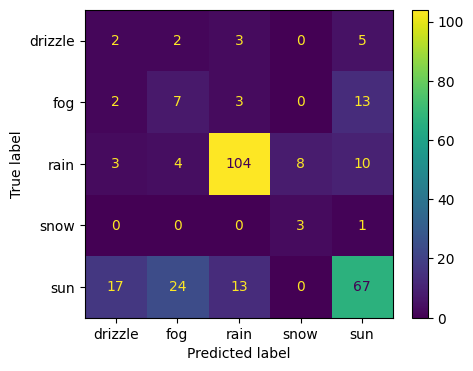

In [28]:
# Task

# Display the confusion matrix using y_test and y_pred, the display lables are "Setosa,", "Versicolour", "Virginica".
fig,ax = plt.subplots(figsize=(5,4),dpi = 100)
cm = confusion_matrix(y_test, y_pred, labels = [0, 1, 2, 3, 4])
cmp = ConfusionMatrixDisplay(cm, display_labels = ["drizzle", "fog", "rain", "snow", "sun"])
cmp.plot(ax = ax);

In [29]:
# Task

# Present the overal report of the model's evaluation results using the method classification_report() in metrics
report = metrics.classification_report(y_test, y_pred, target_names=["drizzle", "fog", "rain", "snow", "sun"])
print(report)

              precision    recall  f1-score   support

     drizzle       0.08      0.17      0.11        12
         fog       0.19      0.28      0.23        25
        rain       0.85      0.81      0.83       129
        snow       0.27      0.75      0.40         4
         sun       0.70      0.55      0.62       121

    accuracy                           0.63       291
   macro avg       0.42      0.51      0.44       291
weighted avg       0.69      0.63      0.65       291



## Section 6

### Predict the class labels for the data samples in the future sample set
Use the futureSample_X to simulate the new data items in a real-world application scenario. Use the method `predict()` to calculate the predicted values of futureSample data and store the values in a variable, `solution_validate`.

In [30]:
# Predicted class lables the samples in the futureSample dataset
if model_option ==3 or model_option == 4 or model_option == 5:
  solution_validate = final_clf.predict(futureSample_X_s)
else:
  solution_validate = final_clf.predict(futureSample_X)

In [31]:
# Task

# Calculate the prediction accuracy
score_validate = accuracy_score(futureSample_y, solution_validate)
print (score_validate)

1.0
